**Aim:** anlysis of scRNA-seq data

**Tools**: 
1. Preprocessing: [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
2. Normalization/denoising/imputation of expression: [`scvi`](https://docs.scvi-tools.org/en/stable/user_guide/models/scvi.html)

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import scez

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Global seed set to 0
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)


scanpy==1.9.3 anndata==0.8.0 umap==0.5.3 numpy==1.23.5 scipy==1.10.1 pandas==2.0.0 scikit-learn==1.2.2 statsmodels==0.13.5 python-igraph==0.10.3 pynndescent==0.5.8


# 1. Preprocessing

## Run `scVI`

### Prepare data 

In [3]:
results_file = 'preprocessing/adata-cleaned-v2.h5ad.gz'

adata0 = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Exclude female!?

In [4]:
adata0 = adata0[~adata0.obs.cond.str.contains('female')].copy()

___
https://docs.scvi-tools.org/

In [5]:
adata = adata0.copy()

In [12]:
adata.layers["counts"] = adata.X.copy() # preserve counts
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata # freeze the state in `.raw`

In [15]:
adata.layers["counts_norm"] = adata.X.copy()

___

In [19]:
adata.to_df(layer='counts').max().max()

9593.0

In [20]:
adata.to_df(layer='counts_norm').max().max()

9.046857

https://docs.scvi-tools.org/en/stable/tutorials/notebooks/api_overview.html#Loading-and-preparing-data
> Finally, we perform feature selection, to reduce the number of features (genes in this case) used as input to the scvi-tools model. For best practices of how/when to perform feature selection, please refer to the model-specific tutorial. For scVI, we recommend anywhere from 1,000 to 10,000 HVGs, but it will be context-dependent.


In [22]:
adata.var_names_make_unique()

In [24]:
sc.pp.highly_variable_genes(
    adata, #min_mean=0.0125, max_mean=3, min_disp=0.5,
    n_top_genes=10000,
    subset=True,
    # layer="counts",
    flavor="cell_ranger",
    batch_key="batch"
)

#### Run `scvi`

In [27]:
scvi.model.SCVI.setup_anndata(
    adata,
    layer="counts",
    batch_key="batch",
    categorical_covariate_keys=["batch"], # , "group"
    # continuous_covariate_keys=["percent_mito", "percent_ribo"]
)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [28]:
model = scvi.model.SCVI(adata)

In [29]:
model

SCVI Model with the following params: 
n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb, 
latent_distribution: normal
Training status: Not Trained
Model's adata is minified?: False

In [30]:
model.train(max_epochs=400,train_size=0.8,validation_size=0.2)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


Epoch 400/400: 100%|██████████| 400/400 [51:08<00:00,  7.49s/it, loss=3.55e+03, v_num=1]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [51:08<00:00,  7.67s/it, loss=3.55e+03, v_num=1]


In [31]:
model.save("preprocessing/scvi_model_v2/")

___

Load pre-trained model:

In [ ]:
model = scvi.model.SCVI.load(
    # "preprocessing/scvi_model_v1/", adata=adata, use_gpu=False
    "preprocessing/scvi_model_v2/", adata=adata, use_gpu=False
)

### Obtaining model outputs


In [32]:
latent = model.get_latent_representation()

It’s often useful to store the outputs of scvi-tools back into the original anndata, as it permits interoperability with Scanpy.


In [33]:
adata.obsm["X_scVI"] = latent

In [35]:
adata.layers["scvi_normalized"] = model.get_normalized_expression(
    library_size=10e4
)

In [36]:
results_file = 'preprocessing/adata-denoised-v2.h5ad.gz'

adata.write_h5ad(results_file)

### Plot training epochs ...

In [37]:
model.history.keys()

dict_keys(['kl_weight', 'train_loss_step', 'train_loss_epoch', 'elbo_train', 'reconstruction_loss_train', 'kl_local_train', 'kl_global_train'])

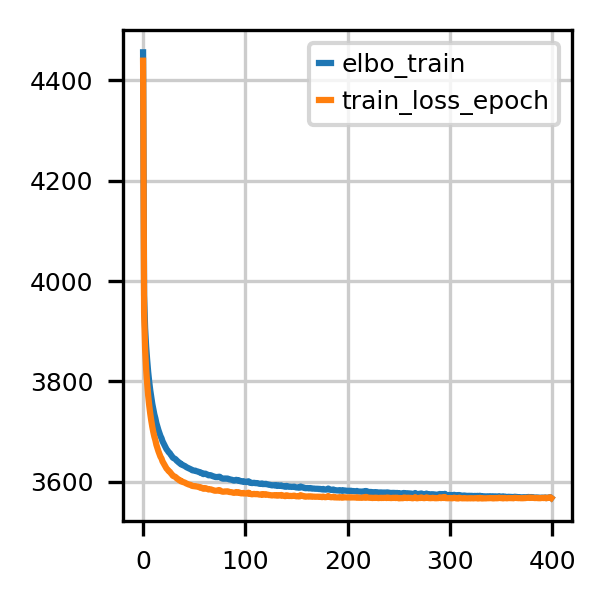

In [40]:
fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(2,2),dpi=150)

ax.plot(model.history["elbo_train"], label="elbo_train")
ax.plot(model.history["train_loss_epoch"], label="train_loss_epoch")
# axes[i].set_ylim(9000, 15000)
ax.legend()

fig.tight_layout()
# fig.savefig('figures/totalVI_training.pdf')

## Explore

In [ ]:
results_file = 'preprocessing/adata-denoised-v2.h5ad.gz'

adata = sc.read_h5ad(results_file)

raw counts

In [ ]:
# # run PCA then generate UMAP plots
# sc.tl.pca(adata)
# sc.pp.neighbors(adata, n_pcs=30, n_neighbors=20)
# sc.tl.umap(adata, min_dist=0.1)

In [ ]:
# sc.pl.umap(
#     adata,
#     color=["batch"],
#     frameon=False,alpha=0.5,size=10
# )

scvi counts

In [41]:
scez.clustering(
    adata,
    rep='X_scVI',
    n_comps = 10,
    n_neighbor = 30,
    res = 0.75,
    key="leiden_scVI"
)

In [42]:
# # use scVI latent space for UMAP generation
# sc.pp.neighbors(adata, use_rep="X_scVI")
# sc.tl.umap(adata, min_dist=0.3)

In [43]:
# # neighbors were already computed using scVI
# sc.tl.leiden(adata, key_added="leiden_scVI", resolution=0.75)

### UMAP after denoising 

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


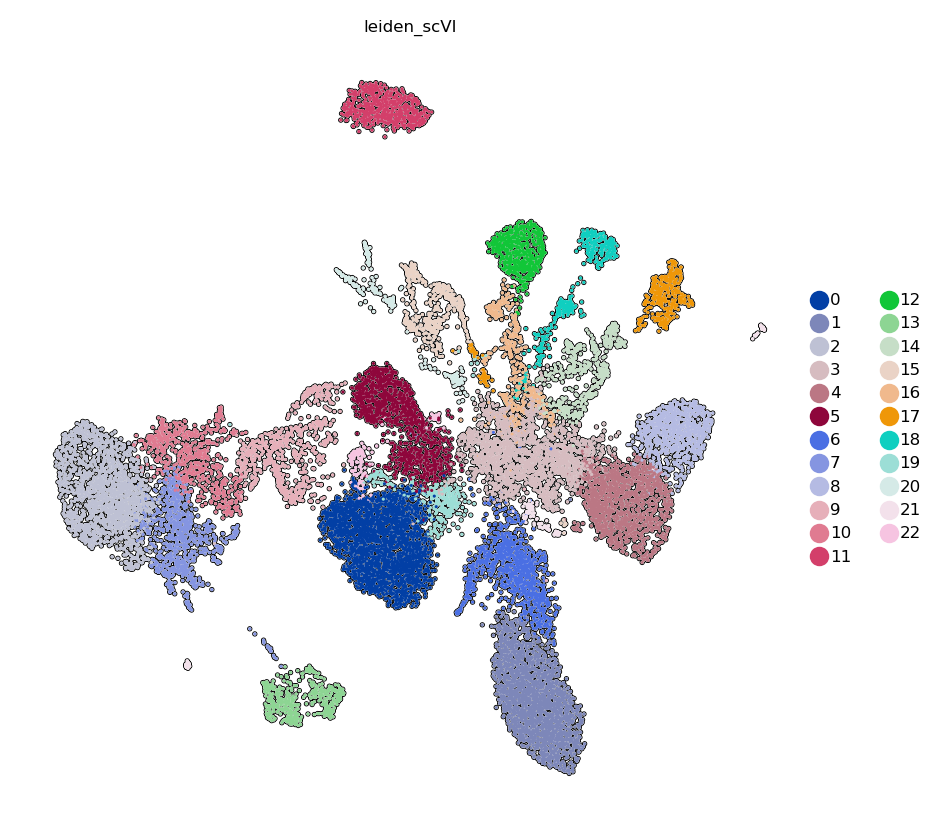

In [48]:
sc.pl.umap(
    adata,
    color=[#'group',"batch",
           'leiden_scVI'],
    frameon=False,alpha=1,size=5,
    add_outline=0.1
)

# 

In [51]:
results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'

adata.write_h5ad(results_file)

In [52]:
!date

Mon Apr  3 18:15:10 PDT 2023
